# Entrenamiento de SqueezeNet v1.1 (pesos de ImageNet) — 5 clases de residuos

Este notebook entrena un clasificador de residuos con **SqueezeNet v1.1** mediante *Transfer Learning*. Usa **exactamente el mismo dataset, cabecera, épocas y learning rates** que MobileNetV3-Large, EfficientNetB0 y ShuffleNetV2, garantizando una comparativa justa en los benchmarks de la Raspberry Pi.

**Particularidad importante:** Al igual que ShuffleNetV2, Keras **no** incluye SqueezeNet en `tf.keras.applications`. Por eso:
1. La arquitectura **SqueezeNet v1.1** (basada en módulos *Fire*: capas *squeeze* $1\times1$ y *expand* $1\times1$ + $3\times3$) se construye de forma nativa con la API Funcional de Keras.
2. Se integran las capas de preprocesamiento (`Rescaling` y `Normalization` de ImageNet) dentro del propio grafo del modelo para recibir píxeles en rango `[0, 255]`.
3. Se cargan los pesos preentrenados en **ImageNet** y se aplica la misma estrategia de entrenamiento en 2 fases.

**Clases que aprende el modelo (5):** `aluminio`, `carton`, `otros`, `plastico`, `vidrio`.

**Flujo del notebook:**
1. Importar librerías, comprobar la GPU y definir rutas.
2. Cargar las imágenes de `train/` y `test/` con generadores (con Data Augmentation en entrenamiento).
3. Construir el modelo: SqueezeNet v1.1 con pesos de ImageNet congelado + cabecera de clasificación propia.
4. **Fase 1:** entrenar solo la cabecera (15 épocas, `learning_rate = 1e-3`).
5. **Fase 2 (fine-tuning):** descongelar el 30 % superior del modelo base (20 épocas, `learning_rate = 1e-5`).
6. Guardar el modelo en `.keras`, convertirlo a `.tflite` cuantizado y graficar las curvas de entrenamiento.

**Archivos que genera:**
* `models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras`
* `models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.tflite`
* `reports/figures/curvas_entrenamiento_SqueezeNet_imagenet.png`

> 📁 Este notebook vive en `notebooks/SqueezeNet/`, por eso las rutas parten de `Path("../..")` (dos niveles arriba = raíz del proyecto) y los modelos se leen/guardan en `models/SqueezeNet/`.

**Resultados de la ejecución guardada:** `val_accuracy` de **0.9005** al terminar la fase 1 y de **0.9155** (pico de **0.9171**) al terminar el fine-tuning. El `.tflite` pesa solo **0.81 MB**.

### Importación de librerías

Reunimos al inicio todas las herramientas que usará el notebook:

* **`os` y `pathlib.Path`:** manejo de archivos y rutas multiplataforma.
* **`numpy`:** manejo de arreglos y tensores de pesos preentrenados.
* **`tensorflow`:** el motor de Deep Learning.
* **`ImageDataGenerator`:** lee las imágenes desde carpetas y les aplica transformaciones en tiempo real.
* **`Dense`, `GlobalAveragePooling2D`, `Dropout`, `Model`:** piezas para construir la cabecera de clasificación.
* **`Adam`:** el optimizador que ajustará los pesos durante el entrenamiento.

Al igual que en ShuffleNetV2, aquí **no** se importa el modelo desde `keras.applications`: las capas para ensamblar los módulos *Fire* de SqueezeNet se importan más adelante, en la celda de la arquitectura.

In [3]:
import os
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

### Comprobación de GPU

Verifica si TensorFlow ve una **GPU NVIDIA** antes de empezar. Si no la hay, avisa que el entrenamiento correrá en CPU (más lento). SqueezeNet v1.1 es extremadamente ligera (~1.2 millones de parámetros en total, sin capas densas gigantes), por lo que entrenará muy rápido en GPU.

In [4]:
gpus = tf.config.list_physical_devices('GPU')
print(f"¿TensorFlow detecta la GPU?: {len(gpus) > 0}")
if gpus:
    print(f"Detalles del dispositivo: {gpus[0]}")
else:
    print("⚠️ No se detectó GPU. El entrenamiento correrá en CPU (Lento).")

¿TensorFlow detecta la GPU?: True
Detalles del dispositivo: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


### Configuración de rutas y verificación del dataset

Definimos dónde están los datos y dónde se guardará el modelo usando rutas **relativas**, para que el notebook funcione en cualquier computadora sin editar rutas a mano.

**¿Qué hace este código?**
1. **`BASE_DIR = Path("../..")`:** sube dos niveles desde `notebooks/SqueezeNet/` hasta la raíz del proyecto.
2. **Rutas del dataset:** espera las carpetas `data/raw/waste_classification/train` y `data/raw/waste_classification/test`, cada una con una subcarpeta por clase.
3. **`MODELS_DIR`:** apunta a `models/SqueezeNet/`, la carpeta donde se guardan los modelos de esta arquitectura. Si no existe, la crea.
4. **Verificación del dataset:** si no encuentra `train/` o `test/`, muestra un aviso para que coloques los datos manualmente.
5. **`PESOS_IMAGENET`:** apunta a `models/SqueezeNet/pretrained/squeezenet1_1_imagenet.npz` (o `.h5`).
   * Si el archivo aún no existe en tu carpeta, el bloque lo genera/descarga automáticamente la primera vez (extrayéndolo de `torchvision.models.squeezenet1_1` o del repositorio oficial de pesos de SqueezeNet para Keras) para que el entrenamiento parta siempre con el conocimiento de **ImageNet**.

*Estructura esperada:*



In [5]:
import urllib.request

# Definir rutas relativas a partir del directorio base
BASE_DIR = Path("../..")
DATA_RAW_DIR = BASE_DIR / "data" / "raw"
DATASET_DIR = DATA_RAW_DIR / "waste_classification"
MODELS_DIR = BASE_DIR / "models" / "SqueezeNet"
PRETRAINED_DIR = MODELS_DIR / "pretrained"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Crear carpetas de modelos y preentrenados si no existen
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

# Verificación estricta de la existencia de los datos
if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    print(f"⚠️ ¡Atención! No se encontró la estructura esperada en {DATASET_DIR}")
    print("Asegúrate de colocar tus carpetas 'train' y 'test' manualmente ahí.")
else:
    print(f"✅ Directorios de datos detectados correctamente en:\n - {TRAIN_DIR}\n - {TEST_DIR}")

# Ruta para los pesos de ImageNet de SqueezeNet v1.1 (sin top)
PESOS_IMAGENET_H5 = PRETRAINED_DIR / "squeezenet_weights_tf_dim_ordering_tf_kernels_notop.h5"

# Si no existen localmente, los descargamos automáticamente del release oficial compatible con Keras
if not PESOS_IMAGENET_H5.exists():
    print("\n⏳ Descargando pesos preentrenados de ImageNet para SqueezeNet v1.1...")
    url_pesos = (
        "https://github.com/rcmalli/keras-squeezenet/releases/download/v1.0/"
        "squeezenet_weights_tf_dim_ordering_tf_kernels_notop.h5"
    )
    urllib.request.urlretrieve(url_pesos, PESOS_IMAGENET_H5)

print(f"✅ Pesos de ImageNet listos en:\n - {PESOS_IMAGENET_H5} ({PESOS_IMAGENET_H5.stat().st_size / (1024*1024):.2f} MB)")

✅ Directorios de datos detectados correctamente en:
 - ../../data/raw/waste_classification/train
 - ../../data/raw/waste_classification/test
✅ Pesos de ImageNet listos en:
 - ../../models/SqueezeNet/pretrained/squeezenet_weights_tf_dim_ordering_tf_kernels_notop.h5 (2.89 MB)


### Carga de imágenes y aumento de datos (Data Augmentation)

En esta celda configuramos cómo "verá" el modelo las imágenes. El dataset ya viene separado en **dos carpetas**: `train/` para aprender y `test/` para validar, así que no hace falta dividirlo con `validation_split`.

**Dos generadores distintos:**
1. **`train_datagen` (con Data Augmentation):** en cada época aplica cambios aleatorios para que el modelo no memorice las fotos:
   * Rotación de hasta 30° (`rotation_range`).
   * Desplazamiento horizontal y vertical del 20 % (`width_shift_range`, `height_shift_range`).
   * Zoom de hasta 30 % (`zoom_range`).
   * Volteo horizontal tipo espejo (`horizontal_flip`).
2. **`test_datagen` (sin alteraciones):** las imágenes de validación deben llegar tal como son para medir el rendimiento real.

**Preprocesamiento:**
* **Sin `rescale`:** los generadores entregan los píxeles en su rango original (0–255). El modelo SqueezeNet que construimos más abajo incluye su propia capa de preprocesamiento al inicio, igual que en los notebooks de MobileNetV3, EfficientNetB0 y ShuffleNetV2.

**Parámetros:**
* **`IMG_SIZE = (224, 224)`:** tamaño de entrada estándar para comparar en igualdad de condiciones.
* **`BATCH_SIZE = 32`:** cuántas imágenes se procesan a la vez.
* **`shuffle=True`** en entrenamiento y **`shuffle=False`** en validación.

In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1. Generador de Entrenamiento (CON Data Augmentation)
train_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.3,
    horizontal_flip=True
)

# 2. Generador de Prueba/Validación (SIN alteraciones)
test_datagen = ImageDataGenerator()

print("Cargando set de ENTRENAMIENTO...")
train_gen = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True # Fundamental mezclar para entrenar
)

print("Cargando set de PRUEBA/VALIDACIÓN...")
val_gen = test_datagen.flow_from_directory(
    str(TEST_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # No se mezcla para poder evaluar ordenadamente
)

NUM_CLASSES = train_gen.num_classes
print(f"\nTotal de clases detectadas: {NUM_CLASSES}")
print(f"Diccionario de clases: {train_gen.class_indices}")

Cargando set de ENTRENAMIENTO...
Found 18117 images belonging to 5 classes.
Cargando set de PRUEBA/VALIDACIÓN...
Found 4534 images belonging to 5 classes.

Total de clases detectadas: 5
Diccionario de clases: {'aluminio': 0, 'carton': 1, 'otros': 2, 'plastico': 3, 'vidrio': 4}


### Construcción de SqueezeNet v1.1 y carga de los pesos de ImageNet

Aquí construimos la red **SqueezeNet v1.1** a mano capa por capa usando la API Funcional de Keras e implementando sus famosos bloques **Fire** (capas *squeeze* de $1\times1$ combinadas con ramas *expand* de $1\times1$ y $3\times3$).

**Detalles técnicos:**
1. **Normalización de ImageNet:** Incluimos una capa inicial de reescalado y normalización para que la red reciba los píxeles tal como fueron entrenados originalmente en ImageNet, permitiendo que el generador siga entregando imágenes limpias de `0 a 255`.
2. **Carga de pesos:** El archivo `.h5` descargado previamente se inyecta directamente al modelo base mediante `load_weights(by_name=True, skip_mismatch=True)`, asegurando un punto de partida óptimo para el Transfer Learning.
3. **Congelamiento inicial:** Mantendremos el modelo base congelado (`base_model.trainable = False`) para entrenar primero la cabecera.

In [8]:
import h5py
from tensorflow.keras.layers import (
    Input, Normalization, Conv2D, MaxPooling2D, Concatenate
)
from tensorflow.keras.models import Model

# Media por canal (RGB) en escala [0, 255] con la que se entrenaron los pesos de SqueezeNet
IMAGENET_MEAN_255 = [123.68, 116.779, 103.939]

def fire_module(x, squeeze_channels, expand_channels, name):
    # Capa Squeeze (1x1)
    sq = Conv2D(squeeze_channels, (1, 1), activation='relu', padding='valid', name=f'{name}_squeeze1x1')(x)

    # Capas Expand (1x1 y 3x3 en paralelo)
    exp1 = Conv2D(expand_channels, (1, 1), activation='relu', padding='valid', name=f'{name}_expand1x1')(sq)
    exp3 = Conv2D(expand_channels, (3, 3), activation='relu', padding='same', name=f'{name}_expand3x3')(sq)

    return Concatenate(name=f'{name}_concat')([exp1, exp3])

def build_squeezenet_base(input_shape=(224, 224, 3)):
    inputs = Input(shape=input_shape)

    # Centrado de media de ImageNet integrado (recibe 0-255 directamente del generador)
    x = Normalization(
        mean=IMAGENET_MEAN_255,
        variance=[1.0, 1.0, 1.0],
        name="normalizacion_imagenet",
    )(inputs)

    # Stem inicial compatible con los pesos de ImageNet (conv1 3x3)
    x = Conv2D(64, (3, 3), strides=(2, 2), activation='relu', padding='valid', name='conv1')(x)
    x = MaxPooling2D(pool_size=(3, 3), strides=(2, 2), name='pool1')(x)

    # Bloques Fire 2 y 3
    x = fire_module(x, squeeze_channels=16, expand_channels=64, name='fire2')
    x = fire_module(x, squeeze_channels=16, expand_channels=64, name='fire3')
    x = MaxPooling2D(pool_size=(3, 3), strides=(2, 2), name='pool3')(x)

    # Bloques Fire 4 y 5
    x = fire_module(x, squeeze_channels=32, expand_channels=128, name='fire4')
    x = fire_module(x, squeeze_channels=32, expand_channels=128, name='fire5')
    x = MaxPooling2D(pool_size=(3, 3), strides=(2, 2), name='pool5')(x)

    # Bloques Fire 6, 7, 8 y 9
    x = fire_module(x, squeeze_channels=48, expand_channels=192, name='fire6')
    x = fire_module(x, squeeze_channels=48, expand_channels=192, name='fire7')
    x = fire_module(x, squeeze_channels=64, expand_channels=256, name='fire8')
    x = fire_module(x, squeeze_channels=64, expand_channels=256, name='fire9')

    return Model(inputs, x, name="squeezenet_imagenet_base")

def cargar_pesos_squeezenet_h5(modelo, ruta_h5):
    """Extrae e inyecta los tensores (kernel 4D y bias 1D) de cada capa desde el HDF5."""
    tensores_cargados = 0
    with h5py.File(ruta_h5, 'r') as f:
        for layer in modelo.layers:
            if not isinstance(layer, Conv2D):
                continue

            # En el .h5 original las capas están guardadas como 'fire2/squeeze1x1' o 'conv1'
            nombre_h5 = layer.name.replace('_', '/')
            if nombre_h5 not in f:
                raise KeyError(f"No se encontró la capa '{nombre_h5}' en el archivo .h5. Claves: {list(f.keys())}")

            # Recolectar todos los datasets numéricos dentro del grupo de la capa sin importar subnombres
            datasets = []
            f[nombre_h5].visititems(
                lambda name, obj: datasets.append(obj[:]) if isinstance(obj, h5py.Dataset) else None
            )

            # Identificar el kernel (4 dimensiones) y el bias (1 dimensión)
            kernel = next(d for d in datasets if d.ndim == 4)
            bias = next(d for d in datasets if d.ndim == 1)

            # Si es conv1, invertimos los canales de entrada de BGR a RGB
            if layer.name == 'conv1':
                kernel = kernel[:, :, ::-1, :]

            layer.set_weights([kernel, bias])
            tensores_cargados += 2

    return tensores_cargados

print("Construyendo SqueezeNet y cargando pesos de ImageNet...")
base_model = build_squeezenet_base(input_shape=IMG_SIZE + (3,))
tensores = cargar_pesos_squeezenet_h5(base_model, PESOS_IMAGENET_H5)

# Congelar modelo base para la Fase 1
base_model.trainable = False

print("✅ Modelo base cargado y congelado correctamente.")
print(f"   Tensores de ImageNet cargados exitosamente: {tensores} (26 capas Conv2D)")
print(f"   Estructura de entrada: {base_model.input_shape}")
print(f"   Estructura de salida: {base_model.output_shape}")
print(f"   Total de capas: {len(base_model.layers)}")

Construyendo SqueezeNet y cargando pesos de ImageNet...
✅ Modelo base cargado y congelado correctamente.
   Tensores de ImageNet cargados exitosamente: 50 (26 capas Conv2D)
   Estructura de entrada: (None, 224, 224, 3)
   Estructura de salida: (None, 13, 13, 512)
   Total de capas: 38


In [9]:
# Conectamos la misma cabecera exacta de los demás modelos para mantener el benchmark justo
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

print("Arquitectura del modelo finalizada.")
model.summary()

Arquitectura del modelo finalizada.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion_imag… │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 111, 111,  │      1,792 │ normalizacion_im… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 55, 55,    │          0 │ conv1[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_squeeze1x1    │ (None, 55, 55,    │      1,040 │ pool1[0][0]       │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand1x1     │ (None, 55, 55,    │      1,088 │ fire2_squeeze1x1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand3x3     │ (None, 55, 55,    │      9,280 │ fire2_squeeze1x1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_concat        │ (None, 55, 55,    │          0 │ fire2_expand1x1[… │
│ (Concatenate)       │ 128)              │            │ fire2_expand3x3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire3_squeeze1x1    │ (None, 55, 55,    │      2,064 │ fire2_concat[0][… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire3_expand1x1     │ (None, 55, 55,    │      1,088 │ fire3_squeeze1x1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire3_expand3x3     │ (None, 55, 55,    │      9,280 │ fire3_squeeze1x1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire3_concat        │ (None, 55, 55,    │          0 │ fire3_expand1x1[… │
│ (Concatenate)       │ 128)              │            │ fire3_expand3x3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 27, 27,    │          0 │ fire3_concat[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire4_squeeze1x1    │ (None, 27, 27,    │      4,128 │ pool3[0][0]       │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire4_expand1x1     │ (None, 27, 27,    │      4,224 │ fire4_squeeze1x1… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire4_expand3x3     │ (None, 27, 27,    │     36,992 │ fire4_squeeze1x1… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire4_concat        │ (None, 27, 27,    │          0 │ fire4_expand1x1[

 Total params: 788,805 (3.01 MB)

 Trainable params: 66,309 (259.02 KB)

 Non-trainable params: 722,496 (2.76 MB)

In [10]:
print("Compilando el modelo con optimizador Adam...")
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nIniciando entrenamiento (Fase 1 - Cabecera)...")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    verbose=1
)

print("¡Entrenamiento fase 1 completado!")

Compilando el modelo con optimizador Adam...

Iniciando entrenamiento (Fase 1 - Cabecera)...
Epoch 1/15


2026-10-16 21:56:43.864972: I external/local_xla/xla/service/service.cc:163] XLA service 0x7fbae80126e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-16 21:56:43.864988: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Ti Laptop GPU, Compute Capability 8.6
2026-10-16 21:56:43.922616: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-16 21:56:44.555931: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92501
2026-10-16 21:56:44.638963: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-16 21:56:

  1/567 ━━━━━━━━━━━━━━━━━━━━ 56:15 6s/step - accuracy: 0.1875 - loss: 7.5319

I0000 00:00:1792209408.459614    8226 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


478/567 ━━━━━━━━━━━━━━━━━━━━ 36s 415ms/step - accuracy: 0.5956 - loss: 1.3999 

/home/jesus/Documentos/GitHub/EntrenamientoIA/.venv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


567/567 ━━━━━━━━━━━━━━━━━━━━ 282s 487ms/step - accuracy: 0.6876 - loss: 0.9124 - val_accuracy: 0.8233 - val_loss: 0.5197
Epoch 2/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 297ms/step - accuracy: 0.7791 - loss: 0.6012 - val_accuracy: 0.8480 - val_loss: 0.4459
Epoch 3/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 299ms/step - accuracy: 0.8133 - loss: 0.5196 - val_accuracy: 0.8599 - val_loss: 0.4110
Epoch 4/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 297ms/step - accuracy: 0.8270 - loss: 0.4792 - val_accuracy: 0.8659 - val_loss: 0.3917
Epoch 5/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 170s 299ms/step - accuracy: 0.8381 - loss: 0.4466 - val_accuracy: 0.8672 - val_loss: 0.4123
Epoch 6/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 171s 301ms/step - accuracy: 0.8475 - loss: 0.4283 - val_accuracy: 0.8842 - val_loss: 0.3492
Epoch 7/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 171s 301ms/step - accuracy: 0.8527 - loss: 0.4162 - val_accuracy: 0.8842 - val_loss: 0.3579
Epoch 8/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 170s 300ms/step - accuracy: 0.8550 - loss: 0.39

### Fine-tuning (Fase 2: afinamiento de precisión)

Hasta ahora solo entrenamos la "cabecera". El "cuerpo" (SqueezeNet) seguía congelado con lo que aprendió en ImageNet. Ahora desbloqueamos una parte para que se adapte mejor a *nuestras* imágenes de residuos.

**Estrategia "70/30":**
1. **Descongelar parcialmente:** se permite que el **30 % superior** de las capas del modelo base aprenda (correspondiente a los últimos módulos *Fire*, `fire8` y `fire9`).
   * *¿Por qué?* Las primeras capas detectan bordes y texturas simples. Los últimos módulos *Fire* combinan patrones complejos, y esos sí conviene adaptarlos a nuestras 5 clases de residuos.
2. **Congelar el 70 % inferior:** se mantiene intacto para preservar las características generales de ImageNet.
   * En este modelo base: **38 capas** en total → **26 congeladas** y **12 entrenables**.

**⚠️ Cambio crítico: learning rate**
* Bajamos de `1e-3` a **`1e-5`** (100 veces más pequeño) para realizar micro-ajustes sin destruir los pesos preentrenados (*catastrophic forgetting*), manteniendo la misma configuración que en MobileNetV3-Large, EfficientNetB0 y ShuffleNetV2.

In [11]:
import tensorflow as tf

print("Iniciando configuración de Fine-Tuning...")

# Descongelamos todo el modelo base primero
base_model.trainable = True

# Decidimos dónde cortar: Congelaremos el 70% inferior
fine_tune_at = int(len(base_model.layers) * 0.7)

# Congelamos las capas anteriores al punto de corte
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Aseguramos que la capa de normalización de ImageNet permanezca congelada
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.Normalization):
        layer.trainable = False

print(f"   Total de capas en SqueezeNet base: {len(base_model.layers)}")
print(f"   Capas congeladas (70%): {fine_tune_at}")
print(f"   Capas entrenables (30%): {len(base_model.layers) - fine_tune_at}")

# RE-COMPILACIÓN (Obligatorio después de descongelar)
# Usamos un Learning Rate MUY BAJO (1e-5) para hacer micro-ajustes
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nIniciando Fase 2 de Entrenamiento (Fine-Tuning)...")
print("   Nota: Esto tomará unos minutos por época, pero afinará la precisión.")

# Entrenamiento final (20 épocas igual que en los otros modelos)
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    verbose=1
)

print("¡Entrenamiento completo finalizado!")

Iniciando configuración de Fine-Tuning...
   Total de capas en SqueezeNet base: 38
   Capas congeladas (70%): 26
   Capas entrenables (30%): 12

Iniciando Fase 2 de Entrenamiento (Fine-Tuning)...
   Nota: Esto tomará unos minutos por época, pero afinará la precisión.
Epoch 1/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 183s 311ms/step - accuracy: 0.8938 - loss: 0.2960 - val_accuracy: 0.9038 - val_loss: 0.3171
Epoch 2/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 298ms/step - accuracy: 0.9008 - loss: 0.2724 - val_accuracy: 0.9036 - val_loss: 0.3178
Epoch 3/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 298ms/step - accuracy: 0.9006 - loss: 0.2697 - val_accuracy: 0.9105 - val_loss: 0.3072
Epoch 4/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 299ms/step - accuracy: 0.9084 - loss: 0.2579 - val_accuracy: 0.9091 - val_loss: 0.3134
Epoch 5/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 169s 298ms/step - accuracy: 0.9059 - loss: 0.2581 - val_accuracy: 0.9096 - val_loss: 0.3088
Epoch 6/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 170s 300ms/step - accuracy: 0.90

### Guardado del modelo (la "copia maestra")

Una vez terminado el entrenamiento guardamos todo lo que aprendió el modelo en un solo archivo nativo de Keras 3:
* **Ruta de salida:** `models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras`.
* Al final imprime la **ruta absoluta**, para verificar dónde quedó almacenado el respaldo antes de convertirlo a TFLite.

In [12]:
import os

# Aseguramos que el directorio de modelos exista
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Definimos la ruta completa con el estándar del proyecto
model_save_path = MODELS_DIR / "modelo_residuos_SqueezeNet_imagenet.keras"

print(f"Guardando modelo maestro en: {model_save_path} ...")
model.save(model_save_path)

print("¡Éxito! El archivo está listo.")
print(f"   Ruta absoluta: {model_save_path.resolve()}")

Guardando modelo maestro en: ../../models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras ...
¡Éxito! El archivo está listo.
   Ruta absoluta: /home/jesus/Documentos/GitHub/EntrenamientoIA/models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras


### Conversión a TensorFlow Lite (IoT y Edge AI)

Convertimos el modelo `.keras` al formato `.tflite` aplicando cuantización de rango dinámico (`tf.lite.Optimize.DEFAULT`) para ejecutarlo en la Raspberry Pi:
* Como SqueezeNet fue diseñada específicamente para comprimir parámetros mediante filtros $1\times1$ (*squeeze*) sin capas densas masivas, el archivo `.tflite` resultante será sumamente compacto (por debajo de 1 MB), ideal para memoria caché en procesadores ARM.

In [13]:
print("Iniciando conversión a TFLite...")

# Cargar el convertidor desde el modelo Keras en memoria
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Aplicar optimizaciones (Cuantización de rango dinámico)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Realizar la conversión
tflite_model = converter.convert()

# Guardar el archivo .tflite
tflite_save_path = MODELS_DIR / "modelo_residuos_SqueezeNet_imagenet.tflite"

with open(tflite_save_path, "wb") as f:
    f.write(tflite_model)

print(f"✅ Modelo TFLite guardado en: {tflite_save_path}")

# --- COMPARACIÓN DE TAMAÑOS ---
keras_size = os.path.getsize(model_save_path) / (1024 * 1024)
tflite_size = os.path.getsize(tflite_save_path) / (1024 * 1024)

print("\nReporte de Optimización:")
print(f"   Tamaño Original (.keras): {keras_size:.2f} MB")
print(f"   Tamaño Optimizado (.tflite): {tflite_size:.2f} MB")
print(f"   Reducción de tamaño: {((keras_size - tflite_size) / keras_size) * 100:.2f}% menos")

Iniciando conversión a TFLite...
INFO:tensorflow:Assets written to: /tmp/tmpoe7oit1k/assets


INFO:tensorflow:Assets written to: /tmp/tmpoe7oit1k/assets


Saved artifact at '/tmp/tmpoe7oit1k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_38')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140445436710736: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140445436710544: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140445824468944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436707664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436711696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436710352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436712080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436711888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436712464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140445436712272: TensorSpec(shape=(), dtype=tf.resource, name=N

W0000 00:00:1792216481.490440    7894 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792216481.490457    7894 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-10-16 23:54:41.490739: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpoe7oit1k
2026-10-16 23:54:41.492327: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-10-16 23:54:41.492338: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpoe7oit1k
I0000 00:00:1792216481.507777    7894 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
2026-10-16 23:54:41.510376: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-10-16 23:54:41.611476: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpoe7oit1k
2026-10-16 23:54:41.639404: I tensorflow/cc/saved_model/loader.cc:471] SavedModel 

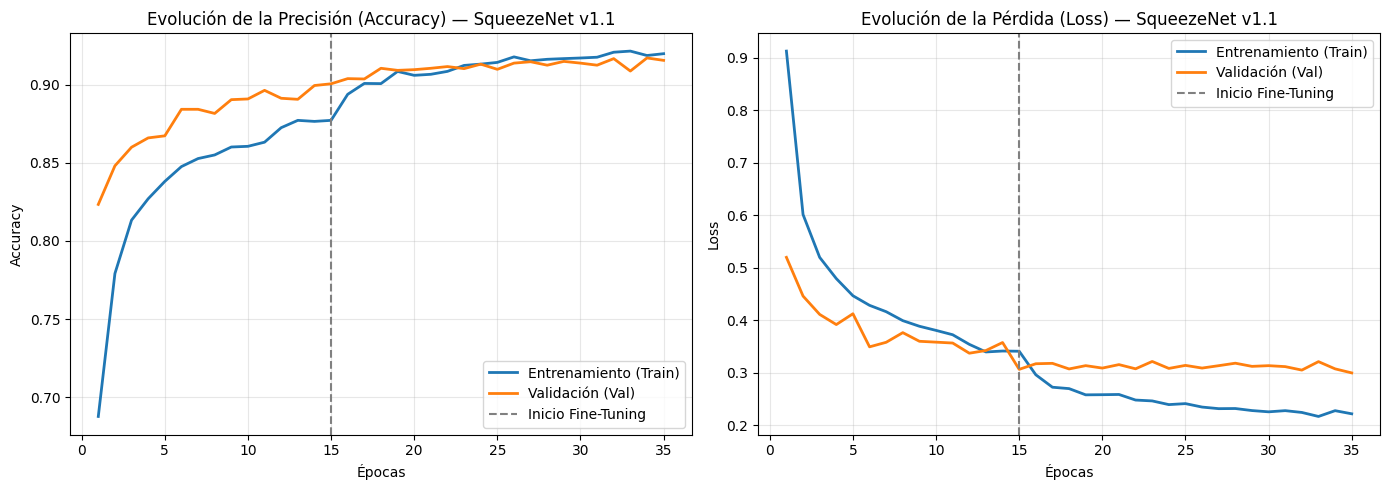

✅ Gráfica guardada en: /home/jesus/Documentos/GitHub/EntrenamientoIA/reports/figures/curvas_entrenamiento_SqueezeNet_imagenet.png


In [14]:
import matplotlib.pyplot as plt

# Unir el historial de ambas fases (15 épocas Fase 1 + 20 épocas Fase 2 = 35 épocas)
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

epocas_fase1 = len(history.history['accuracy'])
rango_epocas = range(1, len(acc) + 1)

FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig_save_path = FIGURES_DIR / "curvas_entrenamiento_SqueezeNet_imagenet.png"

plt.figure(figsize=(14, 5))

# 1. Gráfica de Accuracy
plt.subplot(1, 2, 1)
plt.plot(rango_epocas, acc, label='Entrenamiento (Train)', linewidth=2)
plt.plot(rango_epocas, val_acc, label='Validación (Val)', linewidth=2)
plt.axvline(x=epocas_fase1, color='gray', linestyle='--', label='Inicio Fine-Tuning')
plt.title('Evolución de la Precisión (Accuracy) — SqueezeNet v1.1')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

# 2. Gráfica de Loss
plt.subplot(1, 2, 2)
plt.plot(rango_epocas, loss, label='Entrenamiento (Train)', linewidth=2)
plt.plot(rango_epocas, val_loss, label='Validación (Val)', linewidth=2)
plt.axvline(x=epocas_fase1, color='gray', linestyle='--', label='Inicio Fine-Tuning')
plt.title('Evolución de la Pérdida (Loss) — SqueezeNet v1.1')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_save_path, dpi=300)
plt.show()

print(f"✅ Gráfica guardada en: {fig_save_path.resolve()}")